In [ ]:
import os
import torch
import torch.nn as nn
import copy
import time
import torchvision

from PIL import Image
from torch.utils.data import Dataset, DataLoader 
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import shutil
for name in ['small_cnn', 'mobilenet_v3_small', 'resnet18', 'regnet_x_400mf']:
  shutil.copy(f'{name}.pt', '/content/drive/MyDrive/')

In [33]:
# Learning curves
model_names=['small_cnn', 'mobilenet_v3_small', 'resnet18', 'regnet_x_400mf']
models={}
for name in model_names:
  m=build_model(name)
  m.load_state_dict(torch.load(f'{name}.pt', map_location=device))
  models[name]=m.to(device).eval()


small_cnn
{'train_loss': [0.7317335459545915, 0.3654760194052323, 0.27472108388732513, 0.22406307325969116, 0.18349160616437496, 0.1613049189344489], 'val_loss': [0.4629660575790743, 0.3400658508845135, 0.20073434225885214, 0.3625870439001417, 0.6739072815506859, 0.19059221250359462], 'val_f1': [0.7866705276440822, 0.8629457558762123, 0.9268252214201279, 0.8309595996182861, 0.7314505411457987, 0.9203958166782095]}
range(1, 7)
mobilenet_v3_small
{'train_loss': [0.1578187025955011, 0.04224110784234474, 0.019004006002585346, 0.022911416314891003, 0.013238791986673657, 0.006538077059721685, 0.004570509293860712, 0.0043167438213224715, 0.0020089283121583457], 'val_loss': [0.023015771154610468, 0.015279474401891858, 0.015102266721771986, 0.007804731153300078, 0.0035534785069952367, 0.0018550594490317613, 0.0005241670450261227, 0.000788333451162622, 0.00040129671156381166], 'val_f1': [0.9907566852164645, 0.9964603901834592, 0.993079850847178, 0.9984176150453022, 0.9983680457167932, 0.99944021

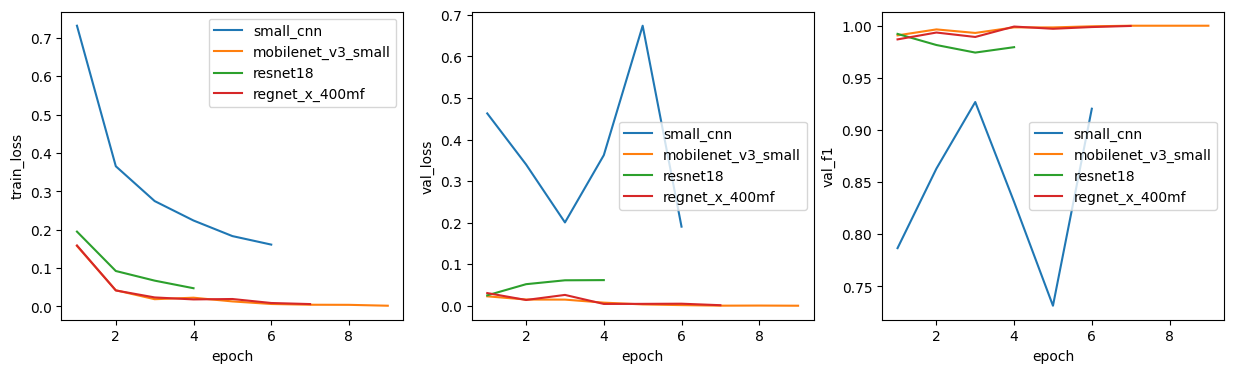

In [37]:
fig, ax=plt.subplots(1,3,figsize=(15,4))
for name, h in histories.items():
  print(name)
  print(h)
  ep=range(1, len(h['val_f1'])+1)
  print(ep)
  ax[0].plot(ep, h['train_loss'],label=name)
  ax[1].plot(ep, h['val_loss'], label=name)
  ax[2].plot(ep, h['val_f1'], label=name)
for a,t in zip(ax, ['train_loss', 'val_loss', 'val_f1']):
  a.set_xlabel('epoch')
  a.set_ylabel(t)
  a.legend()


In [45]:
# test_df evaluation

@torch.no_grad()
def predict(model, loader):
  model.eval()
  probs, labels=[], []
  for x,y in loader:
    probs.append(torch.softmax(model(x.to(device)).float(),1).cpu())
    labels.append(y)
  return torch.cat(probs).numpy(), torch.cat(labels).numpy()

test_out, rows={}, []
for name in model_names:
  probs, labels=predict(models[name], test_loader)
  preds=probs.argmax(1)
  test_out[name]=(probs, labels)
  rows.append({'model':name,
               'accuarcy': accuracy_score(labels, preds),
               'macro_f1': f1_score(labels, preds, average='macro')})
results=pd.DataFrame(rows).set_index('model')


In [46]:
results

,accuarcy,macro_f1
model,,
small_cnn,0.935963,0.927388
mobilenet_v3_small,0.998463,0.998380
resnet18,0.992316,0.986814
regnet_x_400mf,0.997951,0.998349


In [47]:
import time, numpy as np

def cpu_latency_ms(name, runs=50):
    m = build_model(name); m.load_state_dict(torch.load(f'{name}.pt', map_location='cpu')); m.eval()
    torch.set_num_threads(1)
    x, t = torch.randn(1, 3, 224, 224), []
    with torch.no_grad():
        for _ in range(10): m(x)
        for _ in range(runs):
            s = time.perf_counter(); m(x); t.append((time.perf_counter() - s) * 1000)
    return float(np.median(t))

results['params_M'] = [sum(p.numel() for p in models[n].parameters()) / 1e6 for n in results.index]
results['size_MB'] = [os.path.getsize(f'{n}.pt') / 1e6 for n in results.index]
results['cpu_ms'] = [cpu_latency_ms(n) for n in results.index]
results.round(3)

,accuarcy,macro_f1,params_M,size_MB,cpu_ms
model,,,,,
small_cnn,0.936,0.927,0.392,1.580,83.605
mobilenet_v3_small,0.998,0.998,1.530,6.245,35.253
resnet18,0.992,0.987,11.183,44.806,55.943
regnet_x_400mf,0.998,0.998,5.100,20.690,24.976


In [49]:
!pip install onnx onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 62.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 18.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [onnxscript]


In [50]:
m = models['mobilenet_v3_small'].cpu().eval()
torch.onnx.export(m, torch.randn(1, 3, 224, 224), 'mobilenet_v3_small.onnx',
                  input_names=['image'], output_names=['logits'],
                  dynamic_axes={'image': {0: 'batch'}}, opset_version=17)

/tmp/ipykernel_3026/1389320162.py:2: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(m, torch.randn(1, 3, 224, 224), 'mobilenet_v3_small.onnx',
W1031 10:26:41.319000 3026 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 18},
            producer_name='pytorch',
            producer_version='2.11.0+cu130',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"image"<FLOAT,[batch,3,224,224]>
            ),
            outputs=(
                %"logits"<FLOAT,[batch,12]>
            ),
            initializers=(
                %"features.0.0.weight"<FLOAT,[16,3,3,3]>{Tensor(...)},
                %"features.1.block.0.0.weight"<FLOAT,[16,1,3,3]>{Tensor(...)},
                %"features.1.block.1.fc1.weight"<FLOAT,[8,16,1,1]>{TorchTensor(...)},
                %"features.1.block.1.fc1.bias"<FLOAT,[8]>{TorchTensor<FLOAT,[8]>(Parameter containing: tensor([-1.7192e-09, -2.3162e-09, -1.6352e-04, -1.8770e-09, -1.2889e-09, 1.7529e-08, -5.6562e-09,  9.6709e-11], requires_grad=True), name='features.1.block.1.fc1.bias')},
      

In [53]:
import onnxruntime as ort, numpy as np

sess = ort.InferenceSession('mobilenet_v3_small.onnx')
x = torch.randn(4, 3, 224, 224)
onnx_out = sess.run(None, {'image': x.numpy()})[0]
torch_out = m(x).detach().numpy()
print('max difference:', np.abs(onnx_out - torch_out).max())      # expect about 1e-4 or smaller
print('same predictions:', (onnx_out.argmax(1) == torch_out.argmax(1)).all())

max difference: 4.7683716e-06
same predictions: True


In [54]:
correct = 0
for x, y in test_loader:
    out = sess.run(None, {'image': x.numpy()})[0]
    correct += (out.argmax(1) == y.numpy()).sum()
print('ONNX test accuracy:', correct / len(test_df))      # should equal your PyTorch accuracy

ONNX test accuracy: 0.9979518689196109


In [56]:
import onnx
model = onnx.load('mobilenet_v3_small.onnx')       # picks up the .data file next to it
onnx.save_model(model, 'mobilenet_v3_small_single.onnx', save_as_external_data=False)
print(os.path.getsize('mobilenet_v3_small_single.onnx') / 1e6, 'MB')    # expect about 6 MB

6.38232 MB


In [52]:
!pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 42.4 MB/s  0:00:00


In [57]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

name = 'mobilenet_v3_small'
probs, labels = test_out[name]
preds, conf = probs.argmax(1), probs.max(1)
test_df = test_df.reset_index(drop=True)          # row i of test_df = prediction i (the loader did not shuffle)
class_names = selected                             # in label-id order

In [58]:
print(classification_report(labels, preds, target_names=class_names, digits=3))

                                                    precision    recall  f1-score   support

                                 Apple___Black_rot      1.000     1.000     1.000        65
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        29
                 Cherry_(including_sour)___healthy      1.000     1.000     1.000        90
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.982     1.000     0.991        54
                       Corn_(maize)___Common_rust_      1.000     0.992     0.996       125
                                   Grape___healthy      1.000     1.000     1.000        44
          Orange___Haunglongbing_(Citrus_greening)      1.000     1.000     1.000       578
                                   Peach___healthy      1.000     1.000     1.000        38
                              Potato___Late_blight      1.000     1.000     1.000       105
                               Raspberry___healthy      1.000     1.000     1.0

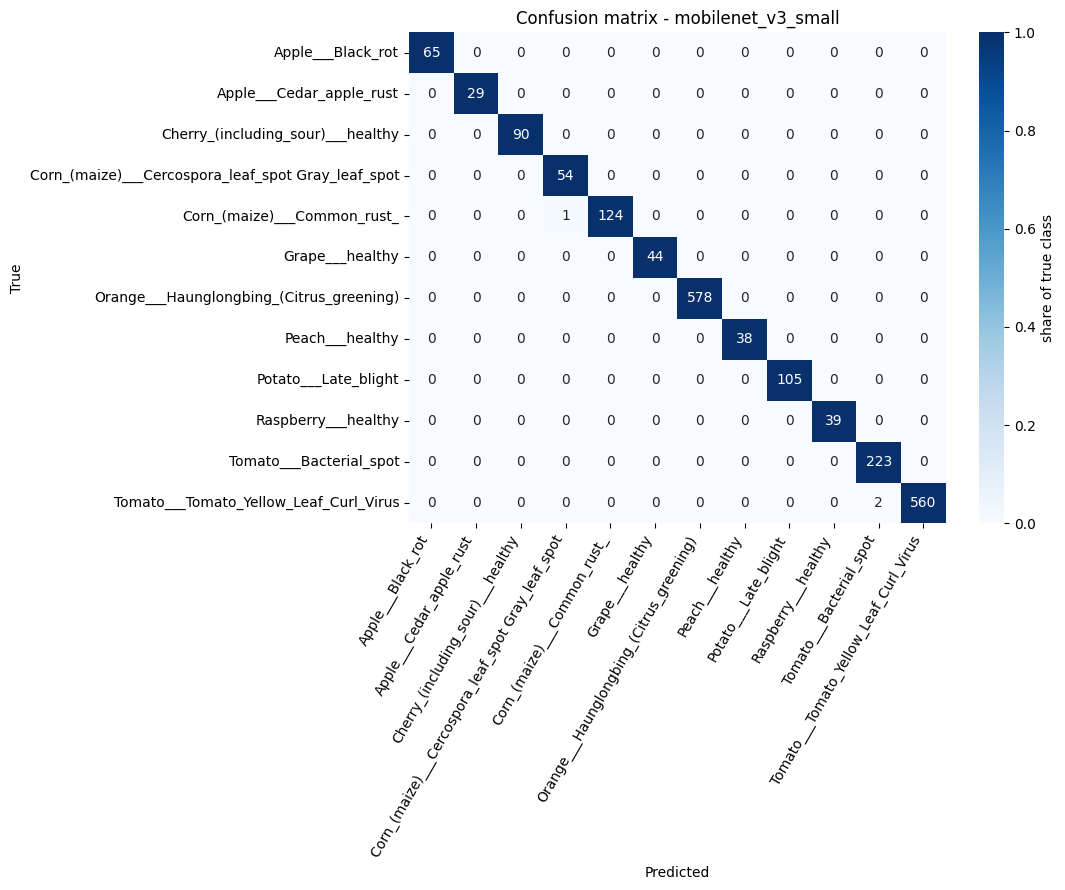

Most frequent confusions (count: true -> predicted):
  2: Tomato___Tomato_Yellow_Leaf_Curl_Virus -> Tomato___Bacterial_spot
  1: Corn_(maize)___Common_rust_ -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot


In [59]:
cm = confusion_matrix(labels, preds, labels=range(len(class_names)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
plt.figure(figsize=(11, 9))
sns.heatmap(cm_norm, annot=cm, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'share of true class'})
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix - {name}')
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

off = [(cm[i, j], class_names[i], class_names[j]) for i in range(len(class_names))
       for j in range(len(class_names)) if i != j and cm[i, j] > 0]
print('Most frequent confusions (count: true -> predicted):')
for n, t, p in sorted(off, reverse=True)[:5]: print(f'  {n}: {t} -> {p}')
if not off: print('  none')

3 wrong out of 1952 test images


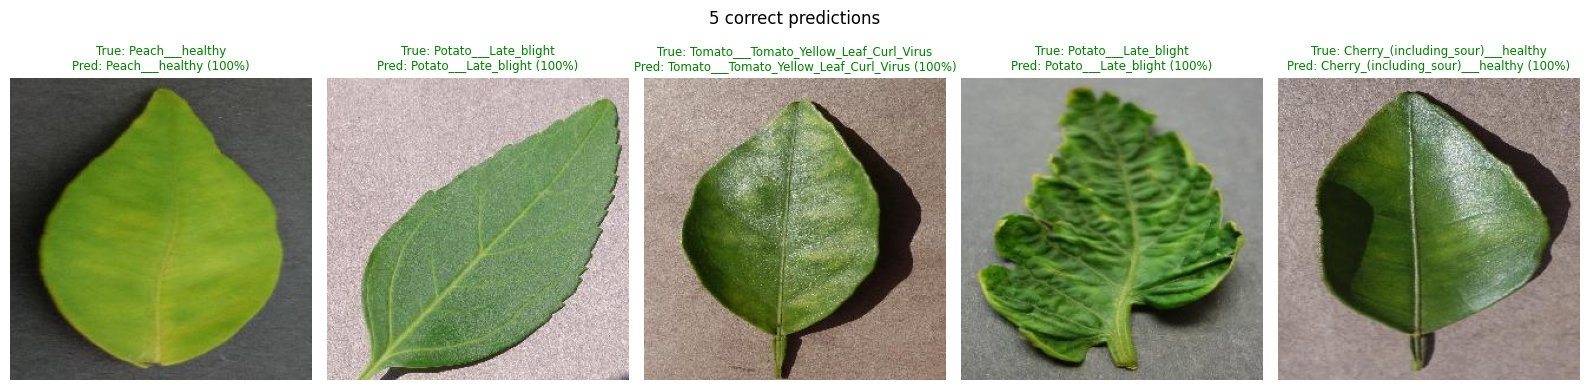

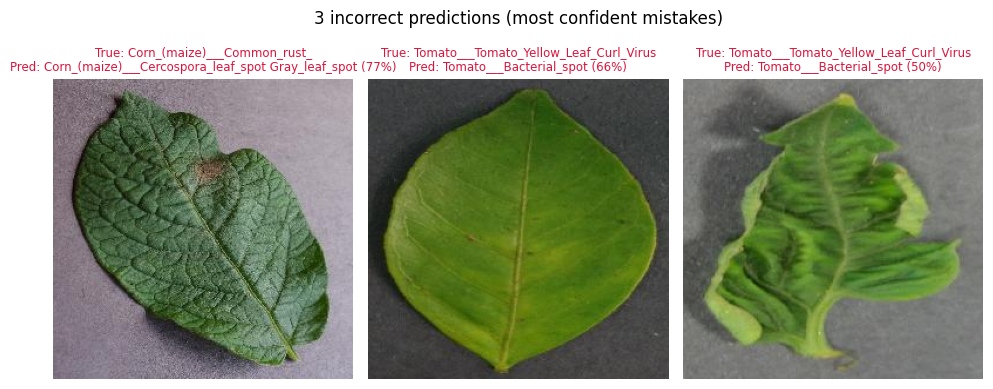

In [60]:
ok_idx, bad_idx = np.where(preds == labels)[0], np.where(preds != labels)[0]
show_ok = np.random.RandomState(42).choice(ok_idx, 5, replace=False)
show_bad = bad_idx[np.argsort(-conf[bad_idx])][:5]        # most confident mistakes first
print(f'{len(bad_idx)} wrong out of {len(labels)} test images')

def grid(indices, title, color):
    if len(indices) == 0:
        print('No examples to show for:', title); return
    fig, ax = plt.subplots(1, len(indices), figsize=(3.2 * len(indices), 3.9), squeeze=False)
    for a, i in zip(ax[0], indices):
        a.imshow(Image.open(test_df.path[i]).convert('RGB')); a.axis('off')
        a.set_title(f'True: {class_names[labels[i]]}\nPred: {class_names[preds[i]]} ({conf[i]:.0%})', fontsize=8.5, color=color)
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

grid(show_ok, '5 correct predictions', 'green')
grid(show_bad, f'{len(show_bad)} incorrect predictions (most confident mistakes)', 'crimson')